class NeuronLoop(GRU):
    def __init__(s, i, h, o, n=2):
        super().__init__(i, h)
        s.n = Linear(h, n)
        s.o = Linear(h, o)
    def forward(s, x):
        x = super().forward(x)[0]
        return s.n(x).softmax(2), s.o(x)
m = NeuronLoop(4, 8, 4, 2)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, .01, 1000, pct_start=.1, div_factor=9, final_div_factor=99)
for i in range(1, O.total_steps):
    x = torch.rand(16,64,4)
    n,y = m(x)    
    l = n[...,0].ravel() @ functional.mse_loss(y,x,reduction='none').mean(2).ravel() +\
        (n[:-1,:,1]*n[1:,:,1]).ravel() @ functional.mse_loss(y[1:],x[:-1],reduction='none').mean(2).ravel()
    # l = functional.mse_loss(y, x)
    l.backward()
    o.step()
    o.zero_grad()
    O.step()
    if not i % 100:
        print(l)

class BatchNorm(BatchNorm1d):
    def forward(s, x):
        return super().forward(x.view(-1,x.size(-1))).view(x.shape)
class Loop(Module):
    def __init__(s, enter, m, exit, logit, out):
        super().__init__()
        s.m = m
        s.enter = enter
        s.m = m
        s.exit = exit
        s.logit = logit
        s.out = out
    def forward(s, x, n=2):
        x = s.enter(x)
        y = []
        for n in range(n):
            x = s.m(x)
            y.append(x)
        y = s.exit(torch.stack(y, 1))
        logit = s.logit(y)[...,0].softmax(1)
        return (logit[:,None] @ s.out(y))[:,0]

def Pool(h, *_, l=[16]):
    return F(
        lambda x, q, *_: [
            x := functional.pad(x, (0, 0, 0, prod(l) - x.size(-2) % prod(l))) if x.size(-2) % prod(l) else x,
            [x := s(torch.cat(torch.broadcast_tensors(q, x.view(-1, l, x.size(-1))), 1))[:, 0] for _, q, l in zip(_, q, l + [x.size(-2) // prod(l)])][-1],
        ][1],
        Parameter(torch.randn(len(_) + 1, h)),
        *_,
    )
class Pool(Sequential):
    def __init__(s, h, *_):
        super().__init__(*_)
        s.q = Parameter(torch.randn(len(_) + 1, h))
    def forward(s, x, l=[16]):
        if x.size(-2) % prod(l):
            x = functional.pad(x, (0, 0, 0, prod(l) - x.size(-2) % prod(l)))
        for s, q, l in zip(s, s.q, l + [x.size(-2) // prod(l)]):
            x = s(torch.cat(torch.broadcast_tensors(q, x.view(-1, l, x.size(-1))), 1))[:, 0]
        return x
class Loop(Module):
    def __init__(s, i, h, o, _=Attention, enter=Nn, exit=Nn):
        super().__init__()
        s._ = _([h, h, h], h)
        s.enter = enter(i, h, h)
        s.exit = exit(h, h, 1 + o)
    def forward(s, x, n=2, N=256):
        x = s.enter(x)[:, None]
        for n in range(n):
            x = torch.cat((x[:, x.size(1) - N :], s._(x)), -2) if x.size(1) < N else s.m(x)
        x = s.exit(x)
        return (x[..., 0].softmax(-1)[..., None, :] @ x[..., 1:])[..., 0, :]

In [ ]:
import torch
import numpy as np
from torch.nn import *
from inspect import stack
from math import prod


class F(Module):
    def __init__(s, f, *_, name=""):
        super().__init__()
        s.f = f
        s._ = _
        s.name = name or (f.__name__ if getattr(f, "__name__", "<lambda>") != "<lambda>" else stack()[1].function)
        for name, _ in enumerate(_):
            if isinstance(_, Module):
                s.add_module(str(name), _)
            elif isinstance(_, Parameter):
                s.register_parameter(str(name), _)

    def forward(s, x):
        return s.f(x, *s._)

    def _get_name(s):
        return s.name


def Seq(*_, f=lambda x, *_: [x := _(x) for _ in _][-1]):
    return F(f, *[_ for _ in _ if not isinstance(_, Identity) for _ in (_._ if isinstance(_, F) and _.f == f else [_])])


def Map(*_, f=lambda x, *_: [_(x) for _ in _]):
    return F(f, *_)


def Add(*_):
    return Seq(Map(*_), F(sum))


def Mul(*_):
    return Seq(Map(*_), F(prod))


@F
def linspace(x):
    return torch.linspace(0, 1, x.size(-2))[:, None]


def Pos(h, _):
    return Add(_, Seq(linspace, Linear(1, h, False)))


@F
def trispace(x):
    return torch.stack([torch.sin(x := torch.linspace(0, 2 * torch.pi, x.size(-2))), torch.cos(x)], 1)


def TriPos(h, _):
    return Add(_, Seq(trispace, Linear(2, h, False)))


@F
def quadspace(x):
    return torch.stack([torch.arange(float(x.size(-2))), x := torch.linspace(0, 2 * torch.pi, x.size(-2)), torch.sin(x), torch.cos(x)], 1)


def QuadPos(h, _):
    return Add(_, Seq(trispace, Linear(4, h, False)))


def Nn(i, h, o=0, bias=True, pos=lambda h, _: _, bn=Identity, act=ReLU(True), head=Linear):
    return Seq(pos(h, head(i, h, bn == Identity)), bn(h, track_running_stats=False), act, *[Linear(h, o)] if o else [])


def SwiGLU(i, h, o=0, bias=True, pos=lambda h, _: _, bn=Identity, act=Hardswish(True), head=Linear):
    return Seq(Mul(Seq(pos(h, head(i, h, bn == Identity)), bn(h, track_running_stats=False), act, name="swi"), Linear(i, h)), *[Linear(h, o)] if o else [])


@F
def AttentionMin(x):
    x = (x if isinstance(x, list) else [x]) * 3
    return (x[0] @ x[1].transpose(-2, -1)).softmax(-1) @ x[2]


def Attention(i, h, o=0, nn=[Nn] * 4, bias=False):
    return Seq(Map(nn[0](i[0], h, h, bias), nn[1](i[1], h, bias and h), nn[2](i[2], h)), AttentionMin, *[nn[3](h, h, o)] if o else [])


@F
def MultiheadAttentionMin(x):
    x = (x if isinstance(x, list) else [x]) * 3
    return torch.einsum("...Llh,...lhk->...Lhk", torch.einsum("...Lhk,...lhk->...Llh", x[0], x[1]).softmax(-2), x[2])


def MultiheadAttention(i, h, o=0, head=1, nn=[Nn] * 4, bias=False):
    return Seq(
        Map(
            Seq(nn[0](i[0], head * h, head * h, bias), Unflatten(-1, [head, h]), name="q"),
            Seq(nn[1](i[1], head * h, head * h, bias), Unflatten(-1, [head, h]), name="k"),
            Seq(nn[2](i[2], head * h, head * h), Unflatten(-1, [head, h]), name="v"),
        ),
        MultiheadAttentionMin,
        Flatten(-2),
        *[nn[3](head * h, head * h, o, head=Identity)] if o else [],
    )

In [ ]:
from dataclasses import dataclass
from IPython.display import clear_output
import matplotlib.pyplot as plt


def Try(f, *_, **__):
    try:
        return f(*_, **__)
    except:
        pass


def plot(plot={}, fig=(12, 8), **dat):
    plt.figure(figsize=fig)
    plt.tight_layout()
    root = None
    line = {}
    for i, (name, dat) in enumerate(dat.items()):
        prefix = name.split("_")[0]
        lin = line.setdefault(prefix, [])
        if lin:
            ax = lin[0].axes
        else:
            if root:
                ax = root.twinx()
                ax.spines.right.set_position(("axes", 1 + (len(line) - 2) * 0.12))
            else:
                ax = root = plt.subplot()
            ax.set(ylabel=prefix)
        lin.append(ax.plot(*dat, **{"c": f"C{i}", "label": name, **plot.get(prefix, {}), **plot.get(name, {})})[0])
    root.legend(handles=sum(line.values(), []))
    return line


class Log(dict):
    i = 1

    def __init__(s, it=10, **_):
        s.it = it
        s._ = _

    def __call__(s, **dat):
        for name, dat in dat.items():
            if dat is not None:
                _ = s.get(name)
                if not _:
                    _ = s[name] = [np.empty(9999, "f"), np.empty([9999, Try(len, dat)] if Try(len, dat) else 9999, "f"), 0, []]
                _[0][_[2] + len(_[3])] = s.i
                _[3].append(dat)
        if not s.i % s.it:
            s.plt()
        s.i += 1

    def sync(s):
        for s in s.values():
            s[1][s[2] : s[2] + len(s[3])] = s[3]
            s[2] += len(s[3])
            s[3].clear()

    def plt(s):
        s.sync()
        plot(**s._, **{i: [s[0][: s[2]], s[1][: s[2]]] for i, s in s.items()})
        clear_output(True)
        plt.show()


@dataclass
class AutoLR:
    o: torch.optim.Optimizer
    exp: float = 0.999
    mom: float = 0.9
    up: float = 1 / 0.999
    down: float = 0.999
    til: float = 1e-5
    los = 0

    def step(s, los):
        s.o.param_groups[0]["lr"] *= s.up if los < s.los * s.exp else s.down
        s.los = (s.los or los) * s.mom + los * (1 - s.mom)
        return s.o.param_groups[0]["lr"] < s.til

In [ ]:
m = 64
m = Seq(
    Add(
        Seq(
            Nn(1, m, m, pos=Pos2, act=SiLU(True)),
            AttentionMin,
        ),
        Linear(1, m, False),
    ),
    Nn(m, m, 8, pos=Pos2, act=SiLU(True)),
)
o = torch.optim.Adam(m.parameters(), 0.02)
O = AutoLR(o=o, exp=0.9995, til=1e-4)
l = 0
while O.step(l, acc=lambda: (y.argmax(2) == x).sum() / x.numel()):
    x = torch.rand(64, 8)
    y = m(x[..., None])
    x = x.argsort()
    l = functional.cross_entropy(y.transpose(1, 2), x)
    l.backward()
    o.step()
    o.zero_grad()

In [ ]:
m = 8
m = Seq(
    *(
        Add(
            Seq(
                Nn(m if i else 1, m, m, pos=Pos2, act=SiLU(True)),
                AttentionMin,
            ),
            Linear(m if i else 1, m, False),
        )
        for i in range(5)
    ),
    Nn(m, m, 32, pos=Pos2, act=SiLU(True)),
)
o = torch.optim.Adam(m.parameters(), 0.02)
O = AutoLR(o=o, exp=0.9995, til=1e-5)
l = 0
while O.step(l, acc=lambda: (y.argmax(2) == x).sum() / x.numel()):
    x = torch.rand(64, 32)
    y = m(x[..., None])
    x = x.argsort()
    l = functional.cross_entropy(y.transpose(1, 2), x)
    l.backward()
    o.step()
    o.zero_grad()

In [ ]:
from random import random

m = 16
m = Seq(
    *(
        Add(
            Seq(
                Nn(m if i else 1, m, m, pos=TriPos, act=SiLU(True)),
                AttentionMin,
            ),
            Linear(m if i else 1, m, False),
        )
        for i in range(8)
    ),
    Nn(m, m, 256, pos=TriPos, act=SiLU(True)),
)
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.0005, 200000, pct_start=0.1, div_factor=9, final_div_factor=999)

In [ ]:
log = Log()
while O.last_epoch < O.total_steps:
    x = torch.rand(64, 256)
    y = m(x[..., None])
    x = x.argsort()
    l = functional.cross_entropy(y.transpose(1, 2), x)
    l.backward()
    o.step()
    o.zero_grad()
    O.step()
    if not (O.last_epoch + 1) % 100:
        log(los=l.detach(), acc=None if (O.last_epoch + 1) % 1000 else (y.argmax(2) == x).sum() / x.numel(), lr=o.param_groups[0]["lr"])

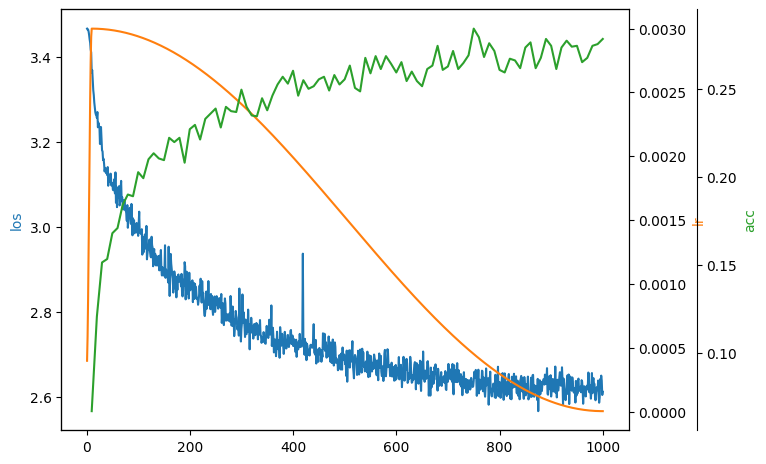